## Part 1: Data Loading & Initial Inspection

In [812]:
# 1. Import important libraries (pandas, numpy, matplotlib, seaborn, sklearn).

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
import sklearn

In [813]:
# 2. Load healthcare-dataset-stroke-data.csv into DataFrame df

df = pd.read_csv("healthcare-dataset-stroke-data.csv")

In [814]:
# 3. Display first 5 rows using df.head()

df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [815]:
# 4. Use df.info() to check data types, non-null values, memory usage

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB


In [816]:
# 5. Use df.describe() for statistical summaries

df.describe().round(2)

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.00,5110.00,5110.0,5110.00,5110.00,4909.00,5110.00
mean,36517.83,43.23,0.1,0.05,106.15,28.89,0.05
std,21161.72,22.61,0.3,0.23,45.28,7.85,0.22
min,67.00,0.08,0.0,0.00,55.12,10.30,0.00
25%,17741.25,25.00,0.0,0.00,77.24,23.50,0.00
50%,36932.00,45.00,0.0,0.00,91.88,28.10,0.00
75%,54682.00,61.00,0.0,0.00,114.09,33.10,0.00
max,72940.00,82.00,1.0,1.00,271.74,97.60,1.00


## Part 2: Exploratory Data Analysis & Visualization

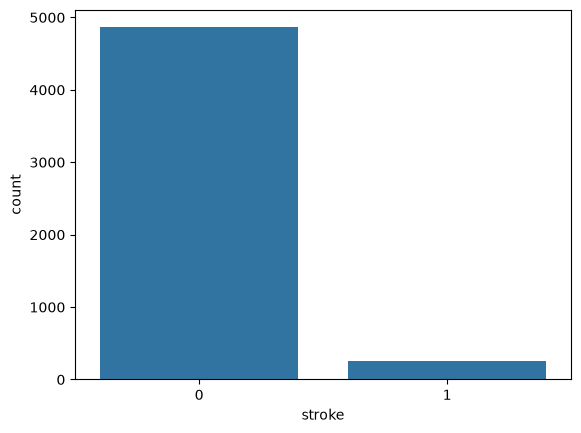

In [817]:
# 1. Create countplot for stroke column (class distribution)

sns.countplot(data=df, x='stroke')
plt.show()

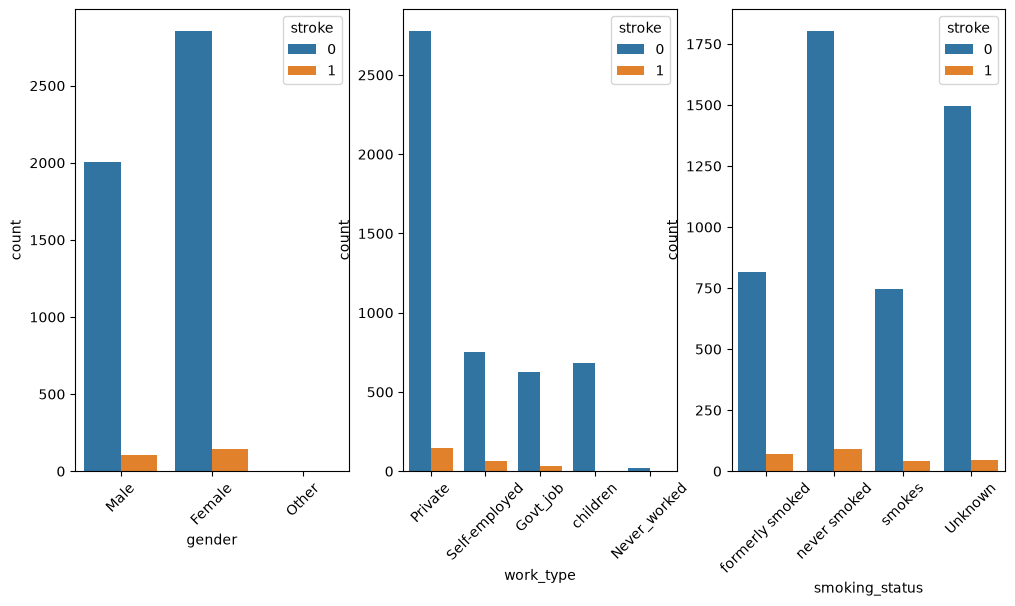

In [818]:
# 2. Create countplots with hue='stroke' for gender, work_type, smoking_status using subplots

plt.figure(figsize=(12,6))
plt.subplot(1,3,1)
sns.countplot(data=df,x='gender', hue='stroke')
plt.xticks(rotation=45)
plt.subplot(1,3,2)
sns.countplot(data=df,x='work_type', hue='stroke')
plt.xticks(rotation=45)
plt.subplot(1,3,3)
sns.countplot(data=df,x='smoking_status', hue='stroke', )
plt.xticks(rotation=45)
plt.show()

In [819]:
# 3. Drop 'Other' gender record (only 1 exists)

print(f"Before ==> {df['gender'].value_counts()}")
df = df[df['gender'] != 'Other']
print(f"\nAfter ==> {df['gender'].value_counts()}")

Before ==> gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

After ==> gender
Female    2994
Male      2115
Name: count, dtype: int64


<Axes: xlabel='bmi', ylabel='Count'>

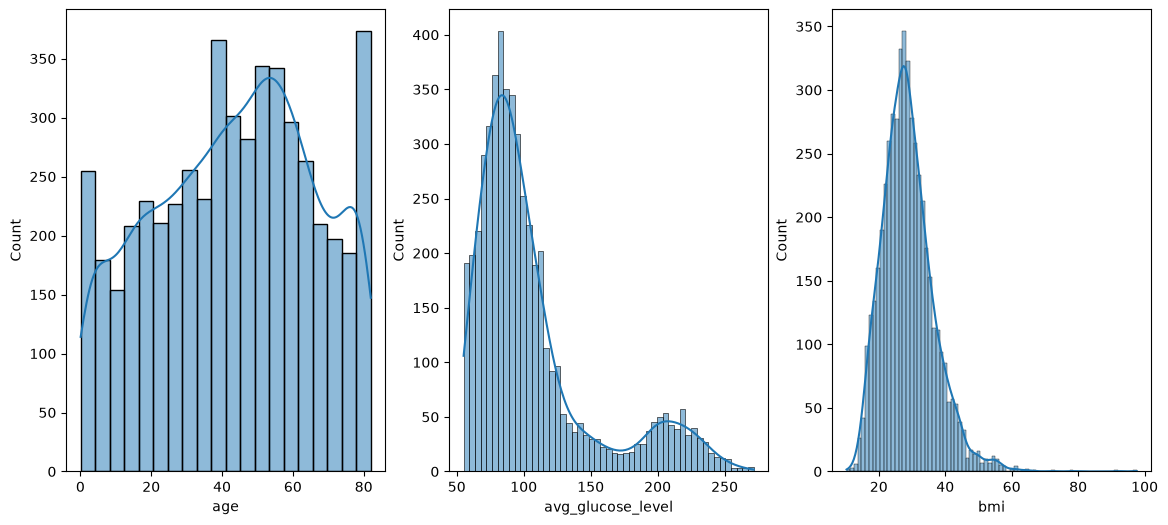

In [820]:
# 4. Create histograms/KDE plots for age, avg_glucose_level, bmi using subplots

plt.figure(figsize=(14,6))
plt.subplot(1,3,1)
sns.histplot(data=df, x='age', kde=True)
plt.subplot(1,3,2)
sns.histplot(data=df, x='avg_glucose_level', kde=True)
plt.subplot(1,3,3)
sns.histplot(data=df, x='bmi', kde=True)

<Axes: >

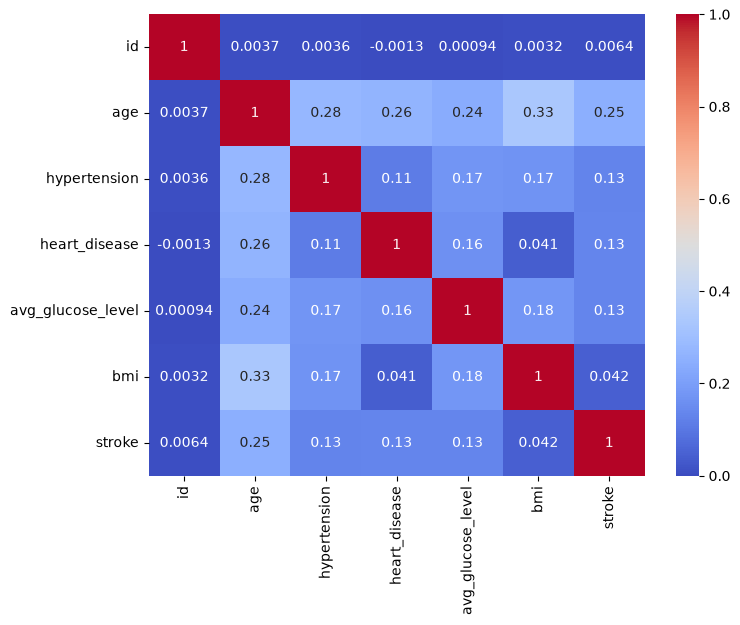

In [821]:
# 5. Create correlation heatmap using selected numerical features and stroke

plt.figure(figsize=(8,6))
num_features = df.select_dtypes(include='number')
sns.heatmap(num_features.corr(), annot=True, cmap='coolwarm')

## Part 3: Data Preprocessing (Cleaning)


In [822]:
# 1. Check for missing values using df.isnull().sum()

df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [823]:
# 2. Fill bmi missing values using mean or median

df['bmi'] = df['bmi'].fillna(df['bmi'].mean())

In [824]:
# 3. Verify no missing values remain

df.isna().sum()

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [825]:
# 4. Check for duplicates and remove them if any exist

df.duplicated().sum()

np.int64(0)

In [826]:
# 5. Drop id column (no predictive power)

df.drop(columns='id', inplace=True)

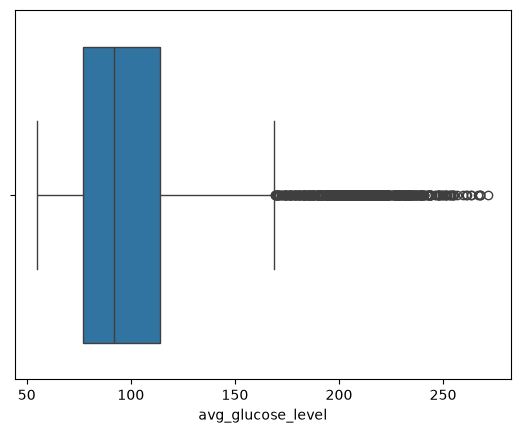

In [827]:
# 6. Create boxplot for avg_glucose_level to detect outliers and remove if needed

sns.boxplot(data=df, x='avg_glucose_level')

q1 = df['avg_glucose_level'].quantile(0.25)
q3 = df['avg_glucose_level'].quantile(0.75)

IQR = q3 - q1 

lower_bound = q1 - 1.5 * IQR
upper_bound= q3 + 1.5 * IQR

df = df[(df['avg_glucose_level'] >= lower_bound) & (df['avg_glucose_level'] <= upper_bound)]

## Part 4: Feature Transformation


In [828]:
# 1. Encode categorical variables: gender, work_type, smoking_status, ever_married, Residence_type

from sklearn.preprocessing import LabelEncoder

lr = LabelEncoder()

df['gender'] = lr.fit_transform(df['gender'])
df['smoking_status'] = lr.fit_transform(df['smoking_status'])
df['ever_married'] = lr.fit_transform(df['ever_married'])
df['Residence_type'] = lr.fit_transform(df['Residence_type'])

In [829]:
# 2. Reset DataFrame index

df.reset_index(drop=True,inplace=True)

In [830]:
# 3. Apply one-hot encoding using pd.get_dummies() or OneHotEncoder

df = pd.get_dummies(df, columns=['work_type'], dtype=int)

## Part 5: Data Splitting


In [831]:
# 1. Separate features X and target y

X = df.drop(columns = 'stroke')
y = df['stroke']

In [832]:
# 2. Use train_test_split() with 80/20 ratio and random_state=42
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [833]:
# 3. Verify shapes of X_train, X_test, y_train, y_test

print(f"Shape of X_train ==> {X_train.shape}")
print(f"Shape of X_test ==> {X_test.shape}")
print("- "*20)
print(f"Shape of y_train ==> {y_train.shape}")
print(f"Shape of y_test ==> {y_test.shape}")

Shape of X_train ==> (3585, 14)
Shape of X_test ==> (897, 14)
- - - - - - - - - - - - - - - - - - - - 
Shape of y_train ==> (3585,)
Shape of y_test ==> (897,)


## Part 6: Feature Scaling


In [834]:
# 1. Import StandardScaler or MinMaxScaler

from sklearn.preprocessing import StandardScaler

In [835]:
# 2. Scale numerical features: age, avg_glucose_level, bmi

numerical_features = ['age', 'avg_glucose_level','bmi']

sr = StandardScaler()

In [836]:
# 3. Fit scaler on training data only, then transform both train and test sets

X_train[numerical_features] = sr.fit_transform(X_train[numerical_features])
X_test[numerical_features] = sr.transform(X_test[numerical_features])

## Part 7: Handling Class Imbalance


stroke
0    3451
1     134
Name: count, dtype: int64


<Axes: xlabel='stroke', ylabel='count'>

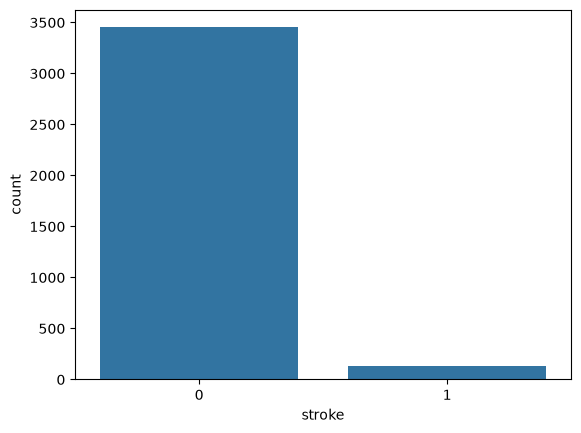

In [837]:
# 1. Check distribution of stroke

print(y_train.value_counts())
sns.countplot(x=y_train)

In [838]:
# 2. Apply oversampling/undersampling or SMOTE

from imblearn.over_sampling import SMOTE

sample = SMOTE(random_state=42)
X_train,y_train = sample.fit_resample(X_train,y_train)

stroke
0    3451
1    3451
Name: count, dtype: int64


<Axes: xlabel='stroke', ylabel='count'>

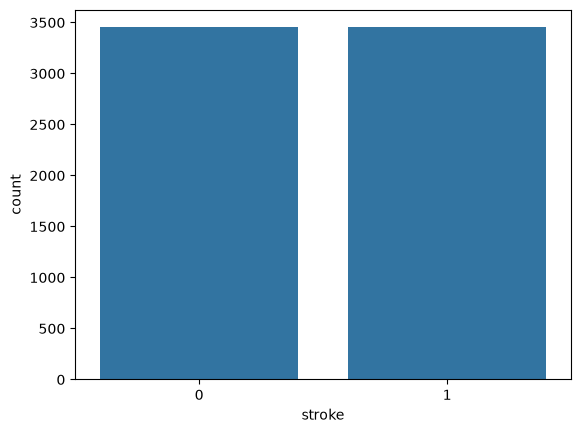

In [839]:
# 3. Verify balanced distribution

print(y_train.value_counts())
sns.countplot(x=y_train)

## Conclusion

In [840]:
# Write a high-risk stroke patient persona and summarize findings.

# gender: Male
# age: 58
# hypertension: 1
# heart_disease: 1
# ever_married: Yes
# Residence_type: Urban 
# avg_glucose_level: 202.21
# bmi: 35.8
# smoking_status: smokes
# stroke: 1

# Summarize findings: The data Base had 201 missing value in bmi column i handle it with the mean of bmi, and the target stroke 
#                     had imbalance distribution for stroke case i handle it by SMOTE, and i use encoding for categorical features,
#                     scaling for numerical features, the data showed that there is relation with stroke and others,
#                     like older age, high blood pressure, high glucose level and BMI, These factors increase a person susceptibility by stoke, 
#                     and after completing the preproccessing, now the data ready to for Machine Learning 